Number of RF parameter combinations: 12
Original data shape: (4139, 245)
                           Unnamed: 0 individual  label  ZKSCAN1  ENPP2  CANX  \
0  vuvum_IGF113090_TTTCACATCAGCTGAT-1    A170/13      0      0.0    0.0   0.0   
1  vuvum_IGF113090_TTGTTTGAGCCGCTTG-1    A170/13      1      0.0    0.0   0.0   
2  vuvum_IGF113090_TGTTGAGAGGATGGCT-1    A170/13      1      0.0    0.0   0.0   
3  vuvum_IGF113090_TGTAACGTCACGAGGA-1    A170/13      0      0.0    0.0   0.0   
4  vuvum_IGF113090_TGGGTTAAGTCAGCGA-1    A170/13      0      0.0    0.0   0.0   

   FOLH1    ZNF638  SLC48A1  MYO6  ...    PITPNB     TNPO3  NEK11  SLC25A33  \
0    0.0  2.096515      0.0   0.0  ...  2.096515  0.000000    0.0       0.0   
1    0.0  0.000000      0.0   0.0  ...  0.000000  0.000000    0.0       0.0   
2    0.0  2.466545      0.0   0.0  ...  0.000000  1.854865    0.0       0.0   
3    0.0  0.000000      0.0   0.0  ...  0.000000  0.000000    0.0       0.0   
4    0.0  2.615516      0.0   0.0  ...  1.992

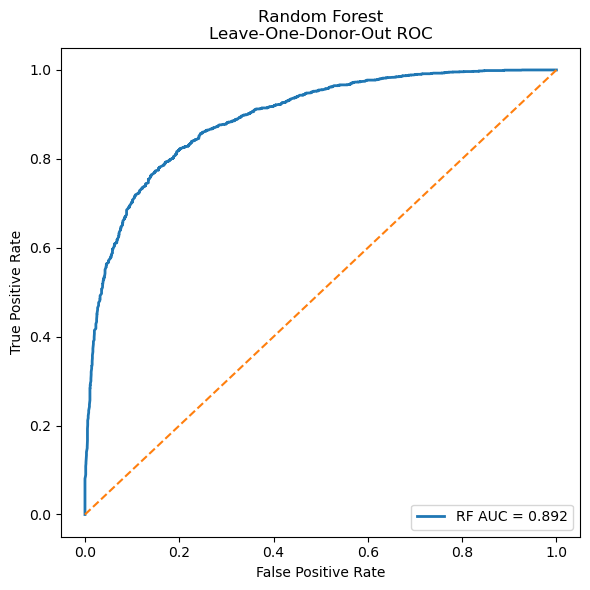

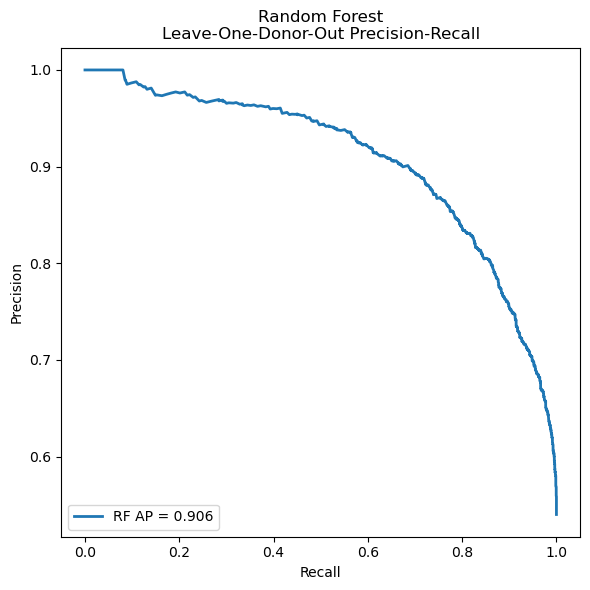

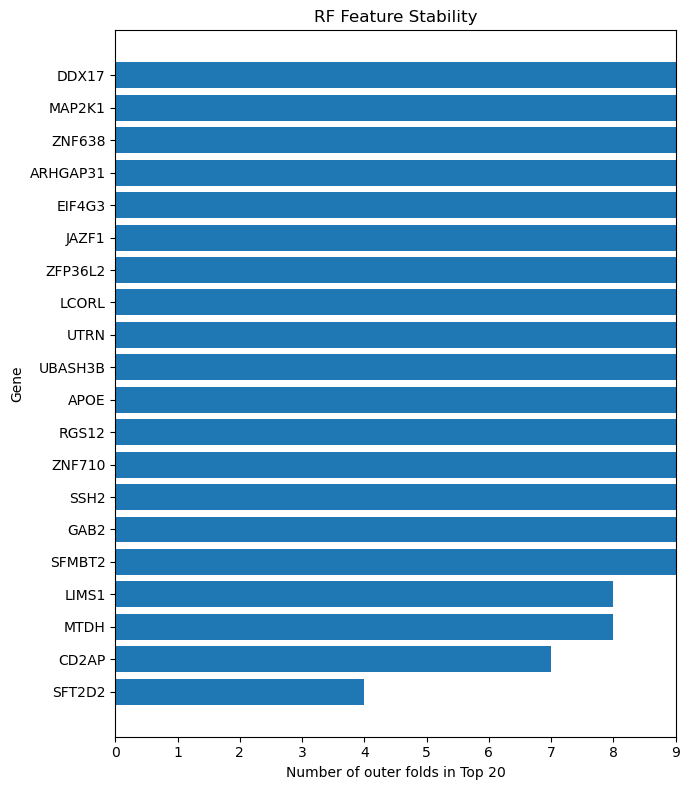

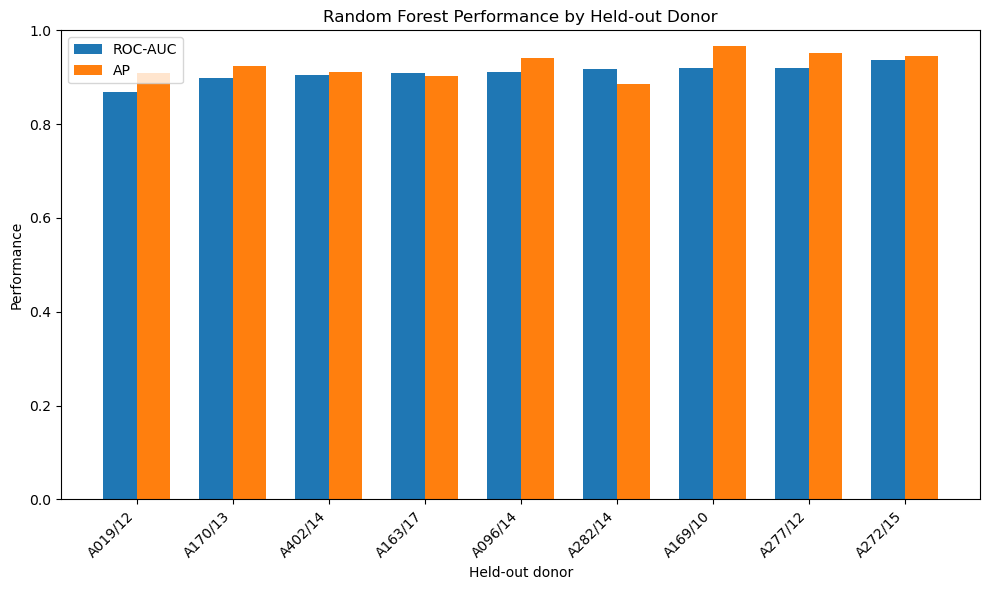



Stable RF genes (Top20 in >= 6/9 folds)
    gene  top20_count  mean_importance  mean_HTS_minus_LTS expression_direction  mean_expression_direction_consistency
  SFMBT2            9         0.038796            0.765162             HTS_high                               1.000000
    GAB2            9         0.024157            0.603623             HTS_high                               1.000000
    SSH2            9         0.024119            0.625295             HTS_high                               1.000000
  ZNF710            9         0.023294            0.516196             HTS_high                               1.000000
   LCORL            9         0.021753            0.450258             HTS_high                               1.000000
 ZFP36L2            9         0.021392            0.448883             HTS_high                               1.000000
   JAZF1            9         0.020325            0.633486             HTS_high                               1.000000
  EIF4

In [1]:
# ============================================================
# Random Forest
# HTS vs LTS
# Nested donor-aware cross-validation
#
# Input:
# AD_microglia_HTS_LTS_TWAS_genes_ML.csv
#
# HTS = 1
# LTS = 0
#
# individual:
# only used for donor-aware splitting
#
# Feature genes:
# Table S3 TWAS-associated genes
# ============================================================


# ============================================================
# 0. Import packages
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)


# ============================================================
# 1. Parameters
# ============================================================

DATA_FILE = "AD_microglia_HTS_LTS_TWAS_genes_ML.csv"

FIG_DIR = "figures"
RESULT_DIR = "results"

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

RANDOM_STATE = 42

TOP_N = 20

# ------------------------------------------------------------
# RF number of trees
#
# 不把n_estimators放进大网格里：
# 树越多主要是提高稳定性，不是典型的过拟合参数。
#
# 300对当前数据足够用于nested CV。
# ------------------------------------------------------------

N_ESTIMATORS = 300


# ============================================================
# 2. RF parameter grid
#
# 12种组合
#
# max_depth:
#   控制树深度
#
# min_samples_leaf:
#   防止树过度拟合单个cells
#
# max_features:
#   每个节点允许考虑多少features
# ============================================================

RF_PARAM_GRID = []

for max_depth in [None, 10]:

    for min_samples_leaf in [1, 5, 10]:

        for max_features in ["sqrt", 0.5]:

            RF_PARAM_GRID.append({

                "max_depth":
                    max_depth,

                "min_samples_leaf":
                    min_samples_leaf,

                "max_features":
                    max_features

            })


print(
    "Number of RF parameter combinations:",
    len(RF_PARAM_GRID)
)


# ============================================================
# 3. Read data
# ============================================================

df = pd.read_csv(
    DATA_FILE
)

print(
    "Original data shape:",
    df.shape
)

print(
    df.head()
)


# ============================================================
# 4. Handle cell barcode column
#
# R:
# write.csv(..., row.names = TRUE)
#
# 通常第一列会变成：
# Unnamed: 0
# ============================================================

first_col = df.columns[0]


if first_col.startswith("Unnamed"):

    df = df.rename(
        columns={
            first_col: "cell"
        }
    )

    df = df.set_index(
        "cell"
    )


elif first_col.lower() in [
    "cell",
    "barcode",
    "cell_barcode"
]:

    df = df.set_index(
        first_col
    )


else:

    df.index = (
        df.index
        .astype(str)
    )

    df.index.name = "cell"


print(
    "\nData after setting cell index:"
)

print(
    df.head()
)


# ============================================================
# 5. Check required columns
# ============================================================

required_columns = [
    "individual",
    "label"
]


for col in required_columns:

    if col not in df.columns:

        raise ValueError(
            f"Missing required column: {col}"
        )


# ============================================================
# 6. Prepare metadata
# ============================================================

df["label"] = (
    df["label"]
    .astype(int)
)

df["individual"] = (
    df["individual"]
    .astype(str)
)


print(
    "\nLabel distribution:"
)

print(
    df["label"]
    .value_counts()
)


print(
    "\nDonor × label:"
)

print(
    pd.crosstab(
        df["individual"],
        df["label"]
    )
)


# ============================================================
# 7. Define genes
#
# individual:
# donor splitting only
#
# label:
# target
#
# all remaining columns:
# TWAS genes
# ============================================================

gene_columns = [

    col

    for col in df.columns

    if col not in [
        "individual",
        "label"
    ]
]


print(
    "\nNumber of genes:",
    len(gene_columns)
)


X = (
    df[
        gene_columns
    ]
    .astype(float)
)

y = (
    df["label"]
    .values
)

groups = (
    df["individual"]
    .values
)

cells = (
    df.index
    .values
)


# ============================================================
# 8. Basic checks
# ============================================================

print(
    "\nNumber of cells:",
    X.shape[0]
)

print(
    "Number of genes:",
    X.shape[1]
)

print(
    "Number of donors:",
    len(
        np.unique(groups)
    )
)


# ------------------------------------------------------------
# Missing
# ------------------------------------------------------------

n_missing = (
    X
    .isna()
    .sum()
    .sum()
)

print(
    "Missing values:",
    n_missing
)


if n_missing > 0:

    raise ValueError(
        "Expression matrix contains missing values."
    )


# ------------------------------------------------------------
# Infinite values
# ------------------------------------------------------------

n_inf = np.isinf(
    X.to_numpy()
).sum()

print(
    "Infinite values:",
    n_inf
)


if n_inf > 0:

    raise ValueError(
        "Expression matrix contains infinite values."
    )


# ------------------------------------------------------------
# Duplicate gene columns
# ------------------------------------------------------------

n_duplicate_genes = (
    pd.Index(
        gene_columns
    )
    .duplicated()
    .sum()
)

print(
    "Duplicated gene columns:",
    n_duplicate_genes
)


# ------------------------------------------------------------
# Zero variance genes
#
# 只检查，不强制删除
# ------------------------------------------------------------

zero_variance_genes = (

    X.columns[
        X.var(axis=0) == 0
    ]
    .tolist()

)

print(
    "Zero variance genes:",
    len(zero_variance_genes)
)


if len(zero_variance_genes) > 0:

    print(
        zero_variance_genes
    )


# ============================================================
# 9. Check every donor contains both HTS and LTS
# ============================================================

donors = np.sort(
    np.unique(groups)
)


for donor in donors:

    donor_y = y[
        groups == donor
    ]

    if len(
        np.unique(donor_y)
    ) < 2:

        raise ValueError(
            f"Donor {donor} does not contain both HTS and LTS."
        )


print(
    "\nDonors:"
)

print(
    donors
)


# ============================================================
# 10. Donor × class balanced sample weights
#
# 每个：
#
# donor × HTS
# donor × LTS
#
# 对训练贡献近似相等
#
# 避免cell很多的donor主导模型
# ============================================================

def make_donor_class_weights(
    groups,
    y
):

    temp = pd.DataFrame({

        "individual":
            groups,

        "label":
            y

    })


    counts = (

        temp

        .groupby(
            [
                "individual",
                "label"
            ]
        )

        .size()

    )


    weights = []


    for donor, label in zip(
        groups,
        y
    ):

        n = counts.loc[
            (
                donor,
                label
            )
        ]

        weights.append(
            1.0 / n
        )


    weights = np.array(
        weights
    )


    # ----------------------------------------
    # normalize:
    # average sample weight = 1
    # ----------------------------------------

    weights = (
        weights /
        weights.mean()
    )


    return weights


# ============================================================
# 11. Build RF model
# ============================================================

def build_rf_model(
    params
):

    model = RandomForestClassifier(

        n_estimators=
            N_ESTIMATORS,

        max_depth=
            params[
                "max_depth"
            ],

        min_samples_leaf=
            params[
                "min_samples_leaf"
            ],

        max_features=
            params[
                "max_features"
            ],

        criterion="gini",

        bootstrap=True,

        random_state=
            RANDOM_STATE,

        n_jobs=-1

    )

    return model


# ============================================================
# 12. Calculate donor-level expression direction
#
# IMPORTANT:
#
# RF feature_importances_没有正负方向。
#
# 所以另外计算：
#
# 每个donor：
# mean(HTS) - mean(LTS)
#
# 再对donor平均。
#
# 这只是表达方向，不是RF importance方向。
# ============================================================

def donor_expression_direction(
    X_input,
    y_input,
    groups_input
):

    donor_deltas = []

    donor_names = []


    for donor in np.unique(
        groups_input
    ):

        donor_mask = (
            groups_input
            ==
            donor
        )


        donor_y = (
            y_input[
                donor_mask
            ]
        )


        if len(
            np.unique(
                donor_y
            )
        ) < 2:

            continue


        X_donor = (
            X_input
            .loc[
                donor_mask
            ]
        )


        hts_mask = (
            donor_y == 1
        )

        lts_mask = (
            donor_y == 0
        )


        mean_hts = (

            X_donor
            .loc[
                hts_mask
            ]
            .mean(
                axis=0
            )

        )


        mean_lts = (

            X_donor
            .loc[
                lts_mask
            ]
            .mean(
                axis=0
            )

        )


        delta = (
            mean_hts
            -
            mean_lts
        )


        donor_deltas.append(
            delta
        )

        donor_names.append(
            donor
        )


    delta_df = pd.DataFrame(
        donor_deltas,
        index=donor_names
    )


    mean_delta = (
        delta_df
        .mean(
            axis=0
        )
    )


    positive_fraction = (

        (
            delta_df > 0
        )

        .mean(
            axis=0
        )

    )


    negative_fraction = (

        (
            delta_df < 0
        )

        .mean(
            axis=0
        )

    )


    direction_consistency = (

        pd.concat(
            [
                positive_fraction,
                negative_fraction
            ],
            axis=1
        )

        .max(
            axis=1
        )

    )


    result = pd.DataFrame({

        "gene":
            X_input.columns,

        "mean_HTS_minus_LTS":
            mean_delta[
                X_input.columns
            ].values,

        "expression_direction_consistency":
            direction_consistency[
                X_input.columns
            ].values

    })


    result[
        "expression_direction"
    ] = np.where(

        result[
            "mean_HTS_minus_LTS"
        ] > 0,

        "HTS_high",

        "LTS_high"

    )


    return result


# ============================================================
# 13. Result containers
# ============================================================

outer_metrics = []

all_predictions = []

all_importances = []

all_top20 = []

all_tuning_results = []


# ============================================================
# 14. Outer Leave-One-Donor-Out CV
# ============================================================

print(
    "\nNumber of outer folds:",
    len(donors)
)


for fold_number, test_donor in enumerate(
    donors,
    start=1
):

    print(
        "\n"
    )

    print(
        "=" * 75
    )

    print(
        f"Outer fold "
        f"{fold_number}/"
        f"{len(donors)}"
    )

    print(
        f"Test donor: "
        f"{test_donor}"
    )

    print(
        "=" * 75
    )


    # ========================================================
    # Outer development / test split
    # ========================================================

    test_mask = (
        groups
        ==
        test_donor
    )

    dev_mask = (
        ~test_mask
    )


    X_dev = (

        X.loc[
            dev_mask
        ]

        .reset_index(
            drop=True
        )

    )


    y_dev = (
        y[
            dev_mask
        ]
    )


    groups_dev = (
        groups[
            dev_mask
        ]
    )


    X_test = (

        X.loc[
            test_mask
        ]

        .reset_index(
            drop=True
        )

    )


    y_test = (
        y[
            test_mask
        ]
    )


    test_cells = (
        cells[
            test_mask
        ]
    )


    print(
        "Development donors:",
        len(
            np.unique(
                groups_dev
            )
        )
    )

    print(
        "Development cells:",
        len(
            y_dev
        )
    )

    print(
        "Test cells:",
        len(
            y_test
        )
    )


    # ========================================================
    # 15. Inner 4-fold donor-aware CV
    # ========================================================

    inner_cv = GroupKFold(
        n_splits=4
    )


    parameter_scores = []


    # ========================================================
    # Test every RF parameter combination
    # ========================================================

    for params in RF_PARAM_GRID:

        inner_AP = []

        inner_ROC = []


        # ----------------------------------------------------
        # Inner donor CV
        # ----------------------------------------------------

        for (
            inner_train_idx,
            inner_val_idx
        ) in inner_cv.split(

            X_dev,
            y_dev,
            groups_dev

        ):


            X_inner_train = (

                X_dev
                .iloc[
                    inner_train_idx
                ]

            )


            y_inner_train = (

                y_dev[
                    inner_train_idx
                ]

            )


            groups_inner_train = (

                groups_dev[
                    inner_train_idx
                ]

            )


            X_inner_val = (

                X_dev
                .iloc[
                    inner_val_idx
                ]

            )


            y_inner_val = (

                y_dev[
                    inner_val_idx
                ]

            )


            groups_inner_val = (

                groups_dev[
                    inner_val_idx
                ]

            )


            # =================================================
            # donor × class training weights
            # =================================================

            train_weights = (

                make_donor_class_weights(

                    groups_inner_train,

                    y_inner_train

                )

            )


            # =================================================
            # RF train
            # =================================================

            model = build_rf_model(
                params
            )


            model.fit(

                X_inner_train,

                y_inner_train,

                sample_weight=
                    train_weights

            )


            # =================================================
            # Inner validation prediction
            # =================================================

            val_prob = (

                model
                .predict_proba(
                    X_inner_val
                )[:, 1]

            )


            # =================================================
            # donor-macro evaluation
            #
            # 每个validation donor分别算：
            # AP
            # ROC-AUC
            #
            # 然后平均
            # =================================================

            val_donors = np.unique(
                groups_inner_val
            )


            for val_donor in val_donors:


                donor_mask = (
                    groups_inner_val
                    ==
                    val_donor
                )


                donor_y = (
                    y_inner_val[
                        donor_mask
                    ]
                )


                donor_prob = (
                    val_prob[
                        donor_mask
                    ]
                )


                if len(
                    np.unique(
                        donor_y
                    )
                ) < 2:

                    continue


                donor_AP = (
                    average_precision_score(

                        donor_y,

                        donor_prob

                    )
                )


                donor_ROC = (
                    roc_auc_score(

                        donor_y,

                        donor_prob

                    )
                )


                inner_AP.append(
                    donor_AP
                )

                inner_ROC.append(
                    donor_ROC
                )


        # ====================================================
        # Average donor-level performance
        # ====================================================

        mean_AP = (
            np.mean(
                inner_AP
            )
        )


        mean_ROC = (
            np.mean(
                inner_ROC
            )
        )


        parameter_scores.append({

            "max_depth":
                params[
                    "max_depth"
                ],

            "min_samples_leaf":
                params[
                    "min_samples_leaf"
                ],

            "max_features":
                params[
                    "max_features"
                ],

            "AP":
                mean_AP,

            "ROC_AUC":
                mean_ROC

        })


        all_tuning_results.append({

            "outer_test_donor":
                test_donor,

            "max_depth":
                params[
                    "max_depth"
                ],

            "min_samples_leaf":
                params[
                    "min_samples_leaf"
                ],

            "max_features":
                params[
                    "max_features"
                ],

            "inner_macro_AP":
                mean_AP,

            "inner_macro_ROC_AUC":
                mean_ROC

        })


    # ========================================================
    # 16. Select best RF parameters
    #
    # Primary metric = AP
    # Secondary = ROC-AUC
    # ========================================================

    parameter_scores_df = pd.DataFrame(
        parameter_scores
    )


    best_row = (

        parameter_scores_df

        .sort_values(

            [
                "AP",
                "ROC_AUC"
            ],

            ascending=[
                False,
                False
            ]

        )

        .iloc[0]

    )


    best_params = {

        "max_depth":

            (
                None
                if pd.isna(
                    best_row[
                        "max_depth"
                    ]
                )
                else int(
                    best_row[
                        "max_depth"
                    ]
                )
            ),

        "min_samples_leaf":

            int(
                best_row[
                    "min_samples_leaf"
                ]
            ),

        "max_features":

            best_row[
                "max_features"
            ]

    }


    # pandas有时会把0.5读取成字符串/对象
    # 转回float
    if best_params[
        "max_features"
    ] != "sqrt":

        best_params[
            "max_features"
        ] = float(
            best_params[
                "max_features"
            ]
        )


    print(
        "\nBest RF parameters:"
    )

    print(
        best_params
    )


    print(
        "Inner macro AP:",
        round(
            best_row[
                "AP"
            ],
            4
        )
    )


    print(
        "Inner macro ROC-AUC:",
        round(
            best_row[
                "ROC_AUC"
            ],
            4
        )
    )


    # ========================================================
    # 17. Retrain RF using all development donors
    # ========================================================

    dev_weights = (

        make_donor_class_weights(

            groups_dev,

            y_dev

        )

    )


    final_model = build_rf_model(
        best_params
    )


    final_model.fit(

        X_dev,

        y_dev,

        sample_weight=
            dev_weights

    )


    # ========================================================
    # 18. Predict completely held-out donor
    # ========================================================

    test_prob = (

        final_model

        .predict_proba(
            X_test
        )[:, 1]

    )


    test_pred = (

        test_prob
        >= 0.5

    ).astype(
        int
    )


    # ========================================================
    # 19. Outer test performance
    # ========================================================

    test_ROC = (
        roc_auc_score(

            y_test,

            test_prob

        )
    )


    test_AP = (
        average_precision_score(

            y_test,

            test_prob

        )
    )


    print(
        "Outer ROC-AUC:",
        round(
            test_ROC,
            4
        )
    )


    print(
        "Outer AP:",
        round(
            test_AP,
            4
        )
    )


    outer_metrics.append({

        "fold":
            fold_number,

        "test_donor":
            test_donor,

        "max_depth":
            best_params[
                "max_depth"
            ],

        "min_samples_leaf":
            best_params[
                "min_samples_leaf"
            ],

        "max_features":
            best_params[
                "max_features"
            ],

        "n_test_cells":
            len(
                y_test
            ),

        "n_HTS":
            int(
                np.sum(
                    y_test == 1
                )
            ),

        "n_LTS":
            int(
                np.sum(
                    y_test == 0
                )
            ),

        "ROC_AUC":
            test_ROC,

        "AP":
            test_AP

    })


    # ========================================================
    # 20. Save test predictions
    # ========================================================

    prediction_df = pd.DataFrame({

        "cell":
            test_cells,

        "individual":
            test_donor,

        "true_label":
            y_test,

        "predicted_probability":
            test_prob,

        "predicted_label":
            test_pred

    })


    all_predictions.append(
        prediction_df
    )


    # ========================================================
    # 21. RF feature importance
    #
    # IMPORTANT:
    #
    # feature_importances_:
    # magnitude only
    #
    # 没有正负方向
    # ========================================================

    importance = (
        final_model
        .feature_importances_
    )


    importance_df = pd.DataFrame({

        "outer_test_donor":
            test_donor,

        "gene":
            gene_columns,

        "importance":
            importance

    })


    # ========================================================
    # 22. Add donor-level HTS/LTS expression direction
    #
    # 只使用development donors
    # 没有使用outer test donor
    # ========================================================

    direction_df = (

        donor_expression_direction(

            X_dev,

            y_dev,

            groups_dev

        )

    )


    importance_df = (

        importance_df

        .merge(

            direction_df,

            on="gene",

            how="left"

        )

    )


    all_importances.append(
        importance_df
    )


    # ========================================================
    # 23. Top20 genes in this outer fold
    # ========================================================

    top20 = (

        importance_df

        .sort_values(

            "importance",

            ascending=False

        )

        .head(
            TOP_N
        )

        .copy()

    )


    top20[
        "rank"
    ] = np.arange(

        1,

        len(
            top20
        ) + 1

    )


    all_top20.append(
        top20
    )


    print(
        "\nTop 10 genes:"
    )

    print(

        top20[
            [
                "gene",
                "importance",
                "mean_HTS_minus_LTS",
                "expression_direction"
            ]
        ]

        .head(10)

        .to_string(
            index=False
        )

    )


# ============================================================
# 24. Combine all outer-fold results
# ============================================================

outer_metrics_df = pd.DataFrame(
    outer_metrics
)


predictions_df = pd.concat(

    all_predictions,

    ignore_index=True

)


importances_df = pd.concat(

    all_importances,

    ignore_index=True

)


top20_df = pd.concat(

    all_top20,

    ignore_index=True

)


tuning_df = pd.DataFrame(
    all_tuning_results
)


# ============================================================
# 25. Save raw results
# ============================================================

outer_metrics_df.to_csv(

    os.path.join(

        RESULT_DIR,

        "RF_outer_LODO_performance.csv"

    ),

    index=False

)


predictions_df.to_csv(

    os.path.join(

        RESULT_DIR,

        "RF_outer_LODO_predictions.csv"

    ),

    index=False

)


importances_df.to_csv(

    os.path.join(

        RESULT_DIR,

        "RF_all_fold_importances.csv"

    ),

    index=False

)


top20_df.to_csv(

    os.path.join(

        RESULT_DIR,

        "RF_top20_each_fold.csv"

    ),

    index=False

)


tuning_df.to_csv(

    os.path.join(

        RESULT_DIR,

        "RF_inner_parameter_tuning.csv"

    ),

    index=False

)


# ============================================================
# 26. Count Top20 frequency
#
# 一个基因在9个outer folds中
# 有多少次进入Top20
# ============================================================

top20_frequency = (

    top20_df

    .groupby(
        "gene"
    )

    .agg(

        top20_count=(
            "outer_test_donor",
            "nunique"
        )

    )

    .reset_index()

)


# ============================================================
# 27. Importance summary across outer folds
# ============================================================

importance_summary = (

    importances_df

    .groupby(
        "gene"
    )

    .agg(

        mean_importance=(
            "importance",
            "mean"
        ),

        sd_importance=(
            "importance",
            "std"
        ),

        median_importance=(
            "importance",
            "median"
        ),

        mean_HTS_minus_LTS=(
            "mean_HTS_minus_LTS",
            "mean"
        ),

        mean_expression_direction_consistency=(
            "expression_direction_consistency",
            "mean"
        )

    )

    .reset_index()

)


# ============================================================
# 28. Merge stability results
# ============================================================

feature_summary = (

    importance_summary

    .merge(

        top20_frequency,

        on="gene",

        how="left"

    )

)


feature_summary[
    "top20_count"
] = (

    feature_summary[
        "top20_count"
    ]

    .fillna(0)

    .astype(int)

)


# ============================================================
# 29. Stable feature definition
#
# ≥6 / 9 outer folds进入Top20
# ============================================================

feature_summary[
    "stable_top20"
] = (

    feature_summary[
        "top20_count"
    ]

    >= 6

)


# ============================================================
# 30. Expression direction
#
# 注意：
#
# 这是donor-level表达方向
# 不是RF importance方向
# ============================================================

feature_summary[
    "expression_direction"
] = np.where(

    feature_summary[
        "mean_HTS_minus_LTS"
    ] > 0,

    "HTS_high",

    "LTS_high"

)


# ============================================================
# 31. Sort final RF feature ranking
# ============================================================

feature_summary = (

    feature_summary

    .sort_values(

        [
            "top20_count",
            "mean_importance"
        ],

        ascending=[
            False,
            False
        ]

    )

    .reset_index(
        drop=True
    )

)


feature_summary[
    "final_rank"
] = np.arange(

    1,

    len(
        feature_summary
    ) + 1

)


# ============================================================
# 32. Save RF final feature summary
# ============================================================

feature_summary.to_csv(

    os.path.join(

        RESULT_DIR,

        "RF_feature_stability_summary.csv"

    ),

    index=False

)


# ============================================================
# 33. Print RF feature ranking
# ============================================================

print(
    "\n"
)

print(
    "=" * 80
)

print(
    "RF feature stability ranking"
)

print(
    "=" * 80
)


print(

    feature_summary[
        [
            "final_rank",
            "gene",
            "top20_count",
            "mean_importance",
            "median_importance",
            "mean_HTS_minus_LTS",
            "expression_direction",
            "mean_expression_direction_consistency",
            "stable_top20"
        ]
    ]

    .head(30)

    .to_string(
        index=False
    )

)


# ============================================================
# 34. Outer donor performance summary
# ============================================================

roc_median = (

    outer_metrics_df[
        "ROC_AUC"
    ]

    .median()

)


roc_q1 = (

    outer_metrics_df[
        "ROC_AUC"
    ]

    .quantile(
        0.25
    )

)


roc_q3 = (

    outer_metrics_df[
        "ROC_AUC"
    ]

    .quantile(
        0.75
    )

)


ap_median = (

    outer_metrics_df[
        "AP"
    ]

    .median()

)


ap_q1 = (

    outer_metrics_df[
        "AP"
    ]

    .quantile(
        0.25
    )

)


ap_q3 = (

    outer_metrics_df[
        "AP"
    ]

    .quantile(
        0.75
    )

)


print(
    "\n"
)

print(
    "=" * 80
)

print(
    "Outer Leave-One-Donor-Out Performance"
)

print(
    "=" * 80
)


print(

    outer_metrics_df

    .to_string(
        index=False
    )

)


print(
    "\nROC-AUC median [IQR]:"
)

print(

    f"{roc_median:.3f} "
    f"[{roc_q1:.3f}, "
    f"{roc_q3:.3f}]"

)


print(
    "\nAP median [IQR]:"
)

print(

    f"{ap_median:.3f} "
    f"[{ap_q1:.3f}, "
    f"{ap_q3:.3f}]"

)


# ============================================================
# 35. Save performance summary
# ============================================================

performance_summary = pd.DataFrame({

    "metric": [
        "ROC_AUC",
        "AP"
    ],

    "median": [
        roc_median,
        ap_median
    ],

    "Q1": [
        roc_q1,
        ap_q1
    ],

    "Q3": [
        roc_q3,
        ap_q3
    ]

})


performance_summary.to_csv(

    os.path.join(

        RESULT_DIR,

        "RF_performance_summary.csv"

    ),

    index=False

)


# ============================================================
# 36. Pooled OOF ROC
#
# 注意：
# 这个图用于visualization。
#
# 正式性能报告：
# 优先使用上面的9个donor
# median [IQR]
# ============================================================

y_oof = (

    predictions_df[
        "true_label"
    ]

    .values

)


prob_oof = (

    predictions_df[
        "predicted_probability"
    ]

    .values

)


fpr, tpr, _ = roc_curve(

    y_oof,

    prob_oof

)


pooled_roc = roc_auc_score(

    y_oof,

    prob_oof

)


plt.figure(
    figsize=(
        6,
        6
    )
)


plt.plot(

    fpr,

    tpr,

    linewidth=2,

    label=(
        f"RF AUC = "
        f"{pooled_roc:.3f}"
    )

)


plt.plot(

    [
        0,
        1
    ],

    [
        0,
        1
    ],

    linestyle="--"

)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Random Forest\n"
    "Leave-One-Donor-Out ROC"
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()


plt.savefig(

    os.path.join(

        FIG_DIR,

        "RF_LODO_ROC.png"

    ),

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 37. Pooled OOF Precision-Recall
# ============================================================

precision, recall, _ = (

    precision_recall_curve(

        y_oof,

        prob_oof

    )

)


pooled_ap = (

    average_precision_score(

        y_oof,

        prob_oof

    )

)


plt.figure(
    figsize=(
        6,
        6
    )
)


plt.plot(

    recall,

    precision,

    linewidth=2,

    label=(
        f"RF AP = "
        f"{pooled_ap:.3f}"
    )

)


plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Random Forest\n"
    "Leave-One-Donor-Out Precision-Recall"
)

plt.legend(
    loc="lower left"
)

plt.tight_layout()


plt.savefig(

    os.path.join(

        FIG_DIR,

        "RF_LODO_PR.png"

    ),

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 38. Top20 feature stability plot
# ============================================================

plot_df = (

    feature_summary

    .head(
        20
    )

    .copy()

)


plot_df = (

    plot_df

    .sort_values(

        "top20_count",

        ascending=True

    )

)


plt.figure(
    figsize=(
        7,
        8
    )
)


plt.barh(

    plot_df[
        "gene"
    ],

    plot_df[
        "top20_count"
    ]

)


plt.xlabel(
    "Number of outer folds in Top 20"
)

plt.ylabel(
    "Gene"
)

plt.title(
    "RF Feature Stability"
)

plt.xlim(
    0,
    len(donors)
)

plt.tight_layout()


plt.savefig(

    os.path.join(

        FIG_DIR,

        "RF_Top20_feature_stability.png"

    ),

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 39. Donor-level performance figure
#
# 每个donor是一个独立测试样本
# 比pooled ROC更适合观察泛化稳定性
# ============================================================

performance_plot = (

    outer_metrics_df

    .sort_values(
        "ROC_AUC"
    )

    .copy()

)


x = np.arange(
    len(
        performance_plot
    )
)


width = 0.35


plt.figure(
    figsize=(
        10,
        6
    )
)


plt.bar(

    x - width / 2,

    performance_plot[
        "ROC_AUC"
    ],

    width,

    label="ROC-AUC"

)


plt.bar(

    x + width / 2,

    performance_plot[
        "AP"
    ],

    width,

    label="AP"

)


plt.xticks(

    x,

    performance_plot[
        "test_donor"
    ],

    rotation=45,

    ha="right"

)


plt.ylim(
    0,
    1
)

plt.ylabel(
    "Performance"
)

plt.xlabel(
    "Held-out donor"
)

plt.title(
    "Random Forest Performance by Held-out Donor"
)

plt.legend()

plt.tight_layout()


plt.savefig(

    os.path.join(

        FIG_DIR,

        "RF_outer_donor_performance.png"

    ),

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 40. Final checks
# ============================================================

stable_genes = (

    feature_summary[
        feature_summary[
            "stable_top20"
        ]
    ]

)


print(
    "\n"
)

print(
    "=" * 80
)

print(
    "Stable RF genes (Top20 in >= 6/9 folds)"
)

print(
    "=" * 80
)


if len(
    stable_genes
) == 0:

    print(
        "No genes reached >= 6/9 Top20 stability."
    )

else:

    print(

        stable_genes[
            [
                "gene",
                "top20_count",
                "mean_importance",
                "mean_HTS_minus_LTS",
                "expression_direction",
                "mean_expression_direction_consistency"
            ]
        ]

        .to_string(
            index=False
        )

    )


# ============================================================
# 41. Analysis completed
# ============================================================

print(
    "\nAnalysis completed."
)

print(
    f"\nFigures saved to: "
    f"{FIG_DIR}/"
)

print(
    f"Results saved to: "
    f"{RESULT_DIR}/"
)